In [1]:
import pandas as pd
df=pd.read_csv("student-mat.csv",sep=";")
print("Dataset loaded successfully!")
print("Shape:",df.shape)
df.head()

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print(df.head())
print(df.columns)

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       '

In [3]:
print(df.isnull().sum().sum())

0


In [4]:
x=df[["studytime","G1","G2"]]
y=df["G3"]
print("x shape:",x.shape)
print("y shape:",y.shape)


x shape: (395, 3)
y shape: (395,)


In [5]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Training students:",len(x_train))
print("Testing students:",len(x_test))

Training students: 316
Testing students: 79


In [6]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
print("Model training completed!")

Model training completed!


In [7]:
y_pred=model.predict(x_test)
print("Actual marks:",list(y_test[:5]))
print("Predicted marks:",y_pred[:5].round(2))

Actual marks: [10, 12, 5, 10, 9]
Predicted marks: [ 7.26 12.24  3.4   8.2   8.37]


In [9]:
from sklearn.metrics import mean_absolute_error,r2_score
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Mean Absolute Error:",round(mae,2))
print("R2 Score:",round(r2,2))

Mean Absolute Error: 1.27
R2 Score: 0.8


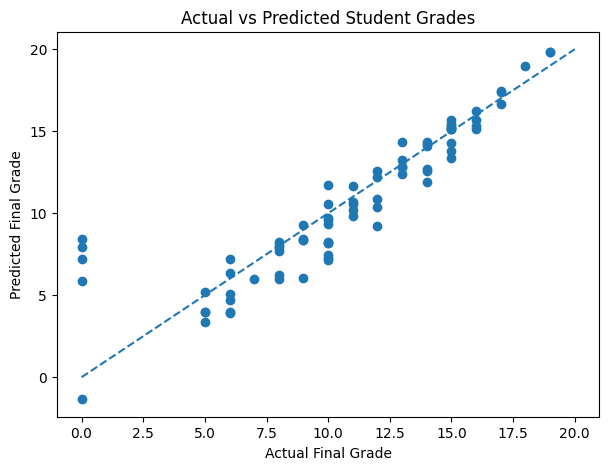

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)
plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")

plt.show()

In [11]:
study_hours = 3
first_grade = 12
second_grade = 14

student = [[study_hours, first_grade, second_grade]]

predicted_grade = model.predict(student)[0]

predicted_grade = max(0, min(20, predicted_grade))

print("Study time:", study_hours)
print("First period grade:", first_grade)
print("Second period grade:", second_grade)
print("Predicted final grade:", round(predicted_grade, 2))

Study time: 3
First period grade: 12
Second period grade: 14
Predicted final grade: 13.77


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [12]:
import ipywidgets as widgets
from IPython.display import display, clear_output

study = widgets.IntSlider(
    value=3, min=1, max=4, description="Study time:"
)

g1 = widgets.IntSlider(
    value=12, min=0, max=20, description="First grade:"
)

g2 = widgets.IntSlider(
    value=14, min=0, max=20, description="Second grade:"
)

button = widgets.Button(
    description="Predict Final Grade",
    button_style="success"
)

output = widgets.Output()

def predict_grade(b):
    with output:
        clear_output()
        prediction = model.predict([[study.value, g1.value, g2.value]])[0]
        prediction = max(0, min(20, prediction))
        print(f"Predicted Final Grade: {prediction:.2f} / 20")

button.on_click(predict_grade)

display(study, g1, g2, button, output)

IntSlider(value=3, description='Study time:', max=4, min=1)

IntSlider(value=12, description='First grade:', max=20)

IntSlider(value=14, description='Second grade:', max=20)

Button(button_style='success', description='Predict Final Grade', style=ButtonStyle())

Output()

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train, y_train)

baseline_pred = baseline.predict(x_test)

print("Our model MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline_pred), 2))
print("Our model R2:", round(r2_score(y_test, y_pred), 2))
print("Baseline R2:", round(r2_score(y_test, baseline_pred), 2))

Our model MAE: 1.27
Baseline MAE: 3.65
Our model R2: 0.8
Baseline R2: -0.01
